# SSH PSD

Compute the Power Spectral Density of SWOT L2_LR_SSH.

Using Welch's method, on a 40km x 40km box.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from swot_healpix.data import SWOT
from swot_healpix.analysis.spectra import SpectraSpecs, cross_psd_2d, psd_2d

In [2]:
track = SWOT(cycle=546, track=19, version="PGC0")
specs = SpectraSpecs()

swot_file = track.get_file()
side = "right"
swot = xr.open_dataset(swot_file, group=side, chunks=-1)

In [3]:
# Extract window for case study

# Study-case a) (long-swell)
i_line = 18810

box = swot.isel(
    num_lines=slice(i_line, i_line + specs.box_size_y),
    num_pixels=slice(specs.box_nadir_side_x, specs.box_nadir_side_x + specs.box_size_x),
)
box.load()

<xarray.Dataset> Size: 3MB
Dimensions:                                (num_lines: 168, num_pixels: 160)
Coordinates:
    latitude                               (num_lines, num_pixels) float64 215kB ...
    longitude                              (num_lines, num_pixels) float64 215kB ...
Dimensions without coordinates: num_lines, num_pixels
Data variables: (12/16)
    time                                   (num_lines) datetime64[ns] 1kB 202...
    time_tai                               (num_lines) datetime64[ns] 1kB 202...
    latitude_uncert                        (num_lines, num_pixels) float64 215kB ...
    longitude_uncert                       (num_lines, num_pixels) float64 215kB ...
    polarization_karin                     (num_lines) object 1kB b'V' ... b'V'
    ssh_karin_2                            (num_lines, num_pixels) float64 215kB ...
    ...                                     ...
    sig0_karin_uncert                      (num_lines, num_pixels) float32 108kB ...
    total_coherence                        (num_lines, num_pixels) float64 215kB ...
    mean_sea_surface_cnescls               (num_lines, num_pixels) float64 215kB ...
    miti_power_250m                        (num_lines, num_pixels) float32 108kB ...
    miti_power_var_250m                    (num_lines, num_pixels) float32 108kB ...
    ancillary_surface_classification_flag  (num_lines, num_pixels) float32 108kB ...
Attributes:
    description:  Unsmoothed SSH measurement data and related information for...

In [4]:
# Flip the left swath to have increasing longitude
if side == "left":
    box = box.isel(num_pixels=slice(None, None, -1))
# Flip to have north up
if track.pass_type == "descending":
    box = box.isel(num_lines=lsice(None, None, -1))

# Remove mean SSH
box["ssh_karin_2"] -= box.ssh_karin_2.mean()

In [5]:
# Center of box
def format_latlon(x, var: str = "lon", fmt: str = ".2f"):
    x = float(x)
    symbols = {"lat": "SN", "lon": "WE"}[var]
    symbol = symbols[x > 0.]
    return f"{{0:{fmt}}}°{{1}}".format(abs(x), symbol)

print("Center of box")
sel = {"num_lines": specs.box_size_y // 2, "num_pixels": specs.box_size_x // 2}
print(format_latlon(box.longitude.isel(**sel), "lon"), format_latlon(box.latitude.isel(**sel), "lat"))

Center of box
141.35°E 46.95°S


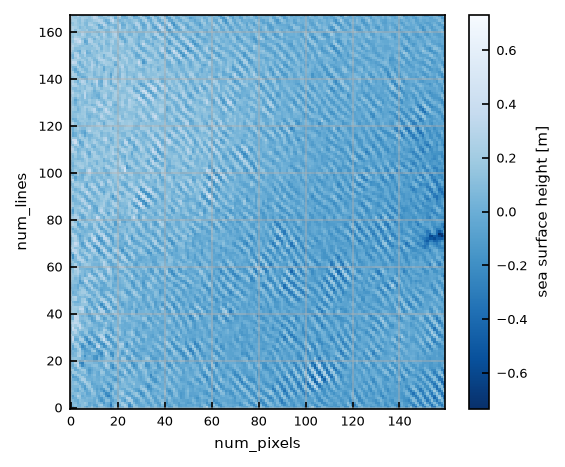

In [6]:
fig, ax = plt.subplots(figsize=(4, 3), layout="constrained", dpi=150)
box.ssh_karin_2.plot.imshow(cmap="Blues_r")
ax.set_aspect("equal")

## Simple PSD

In [7]:
fx, fy = specs.get_frequencies()
fx *= 1000
fy *= 1000
psd1 = psd_2d(box.ssh_karin_2.values, specs)
psd = xr.DataArray(
    10 * np.log10(psd1),
    dims=("fy", "fx"),
    coords={"fx": fx, "fy": fy},
    name="SSH PSD",
    attrs=specs.get_attrs(),
)

psd.attrs["units"] = "db ($m^4$)"
psd.fx.attrs.update({"long_name": "Spatial frequency cross-track", "units": "cycles/km"})
psd.fy.attrs.update({"long_name": "Spatial frequency along-track", "units": "cycles/km"})

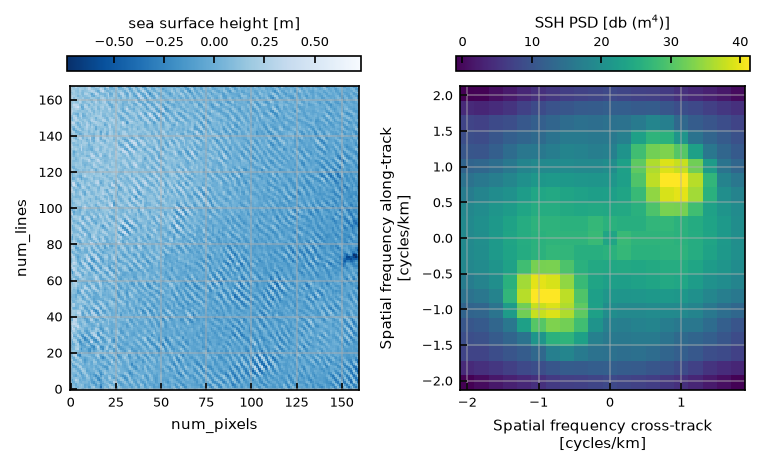

In [8]:
fig, axes = plt.subplots(1, 2, layout="constrained", figsize=(5, 3), dpi=150)
ax1, ax2 = axes

box.ssh_karin_2.plot.imshow(ax=ax1, cmap="Blues_r", cbar_kwargs={"location": "top"})
psd.plot.imshow(ax=ax2, cbar_kwargs={"location": "top"}, center=False)

for ax in axes:
    ax.set_aspect("equal")

## Cross-spectra SSH / backscatter σ0

The cross-spectra can be used to disambiguate the wave direction in some cases.

In [9]:
fx, fy = specs.get_frequencies()
fx *= 1000
fy *= 1000

psd2 = cross_psd_2d(box.sig0_karin_2.values, box.ssh_karin_2.values, specs)

cross_psd = xr.Dataset(
    {
        "psd_ssh": (("fy", "fx"), 10 * np.log10(psd2.psd_b)),
        "psd_sig0": (("fy", "fx"), 10 * np.log10(psd2.psd_a)),
        "psd_coherence": (("fy", "fx"), psd2.coherence),
        "psd_angle": (("fy", "fx"), np.rad2deg(psd2.angle)),
    },
    coords={"fx": fx, "fy": fy},
    attrs=specs.get_attrs(),
)
cross_psd.psd_ssh.attrs.update(
    {"long_name": "PSD of surface elevation", "units": "db ($m^4$)"}
)
cross_psd.psd_sig0.attrs.update(
    {"long_name": "PSD of backscatter", "units": "db ($m^4$)"}
)
cross_psd.psd_coherence.attrs.update({"long_name": "Coherence SSH-$σ_0$"})
cross_psd.psd_angle.attrs.update({"long_name": "Phase angle", "units": "°"})
cross_psd.fx.attrs.update(
    {"long_name": "Spatial frequency cross-track", "units": "cycles/km"}
)
cross_psd.fy.attrs.update(
    {"long_name": "Spatial frequency along-track", "units": "cycles/km"}
)

Text(0, 0.5, 'Spatial frequency along-track\n[cycles/km]')

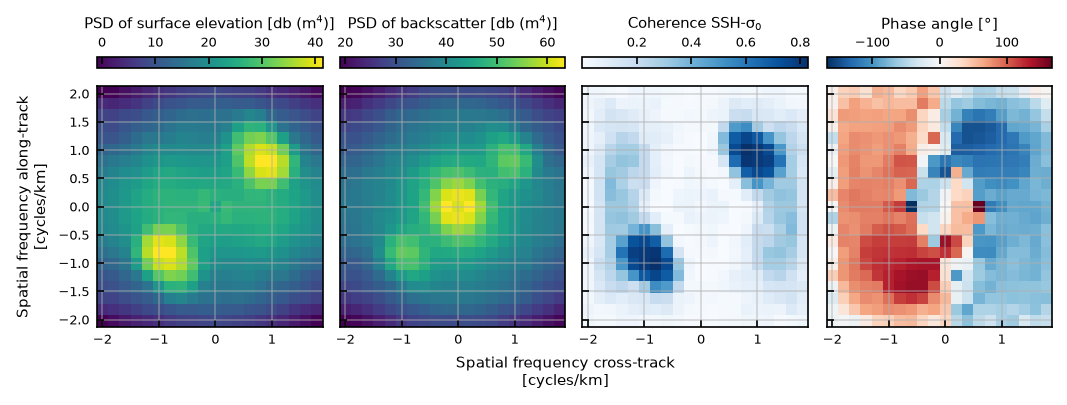

In [10]:
def plot(da, ax, **kw):
    label = da.long_name
    if "units" in da.attrs:
        label = f"{label} [{da.units}]"
    da.plot.imshow(ax=ax, cbar_kwargs={"location": "top", "label": label}, add_labels=False, **kw)

fig, axes = plt.subplots(1, 4, layout="constrained", figsize=(7, 3), dpi=150, sharex=True, sharey=True)

plot(cross_psd.psd_ssh, axes.flat[0], center=False)
plot(cross_psd.psd_sig0, axes.flat[1], center=False)
plot(cross_psd.psd_coherence, axes.flat[2], cmap="Blues")
plot(cross_psd.psd_angle, axes.flat[3])

for ax in axes.flat:
    ax.set_aspect("equal")

axes[1].set_xlabel(f"{cross_psd.fx.long_name}\n[{cross_psd.fx.units}]", x=1)
axes[0].set_ylabel(f"{cross_psd.fy.long_name}\n[{cross_psd.fy.units}]")